# Lab 03: Developing a Tiny Transformer Language Model
**PUSL 3205 – Large Language Models and Generative AI**

In this notebook we build a small GPT-style (decoder-only) Transformer **from scratch in PyTorch**, train it on a subset of the [TinyStories](https://huggingface.co/datasets/roneneldan/TinyStories) dataset with **character-level tokenization**, evaluate it with loss and perplexity, generate stories, experiment with model settings, save the model, and (optionally) build a Gradio chat window.

**How to run:** in Google Colab choose **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**. Total run time is roughly 15–20 minutes on a T4 GPU.

> **Student details:** K.L.D.N.H. Gunathilaka (35167)

## 0. Setup
Install the libraries, import packages, choose the device (GPU if available) and fix the random seed so results are reproducible.
Change the constants in the next cell if you want to train for more or fewer steps.

In [ ]:
%pip install -q datasets gradio

import math, time, json, random, os, itertools
from collections import Counter
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
if device == "cpu":
    print("WARNING: no GPU found. Training will be very slow. Use Runtime > Change runtime type > T4 GPU.")

def set_seed(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(42)

os.makedirs("results", exist_ok=True)   # figures / metrics are saved here as evidence

# ---- Settings you can change ----
N_TRAIN_STORIES = 5000     # stories used for training
N_VAL_STORIES   = 500      # stories used for validation
BLOCK_SIZE      = 128      # context length (characters)
BATCH_SIZE      = 64
MAIN_EPOCHS     =  8      # epochs for the main model
STEPS_PER_EPOCH = 150      # one "epoch" here = 250 training steps (random batches)
EXP_STEPS       = 100      # steps per epoch in the Task 10 experiments
EXP_EPOCHS      = 4        # epochs for the layer / head experiments
EXP_SHORT, EXP_LONG = 2, 8   # epochs for the epoch experiment

Note: you may need to restart the kernel to use updated packages.
Using device: cpu


## 1. Load the dataset
We load `roneneldan/TinyStories` from Hugging Face using **streaming**, so only the stories we need are downloaded rather than the whole multi-gigabyte file.

In [2]:
from datasets import load_dataset

def take_stories(split, n):
    ds = load_dataset("roneneldan/TinyStories", split=split, streaming=True)
    return [row["text"] for row in itertools.islice(ds, n)]

train_stories = take_stories("train", N_TRAIN_STORIES)
val_stories   = take_stories("validation", N_VAL_STORIES)
print(f"Loaded {len(train_stories)} training stories and {len(val_stories)} validation stories")

c:\Users\hesha\anaconda3\envs\llm-lab\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded 5000 training stories and 500 validation stories


### Explore the dataset
Look at several stories, their length and their structure.

In [3]:
for i in range(3):
    print(f"--- Story {i+1} ({len(train_stories[i])} characters) ---")
    print(train_stories[i])
    print()

--- Story 1 (701 characters) ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.

--- Story 2 (705 characters) ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park wh

,characters,words,paragraphs,sentences (approx)
count,5000.0,5000.0,5000.0,5000.0
mean,835.3,162.2,9.1,16.8
std,303.0,60.2,5.6,10.1
min,253.0,48.0,1.0,5.0
25%,670.0,130.0,5.0,12.0
50%,776.0,150.0,8.0,14.0
75%,912.0,176.0,11.0,17.0
max,4123.0,837.0,77.0,122.0


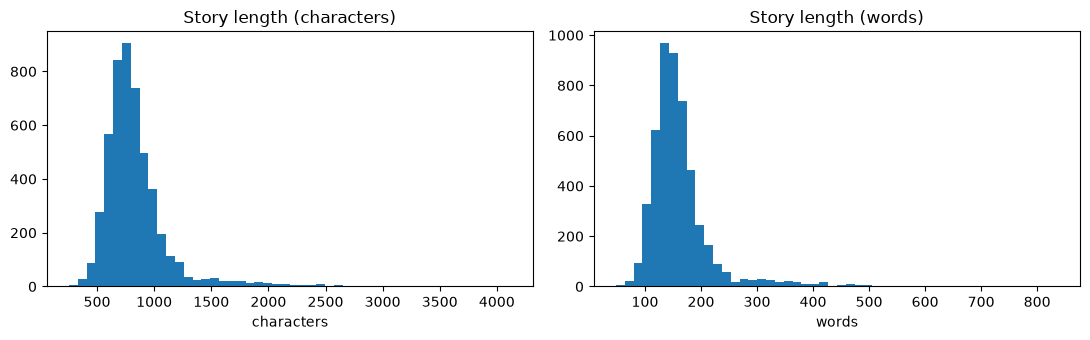

Total training characters: 4,176,740
Example of structure -> first 150 chars of 5 stories:
   'One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the'
   'Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel'
   'One day, a little fish named Fin was swimming near the shore. He saw a big crab and wanted to be friends. "Hi, I am Fin. Do you want to play?" asked t'
   'Once upon a time, in a land full of trees, there was a little cherry tree. The cherry tree was very sad because it did not have any friends. All the o'
   'Once upon a time, there was a little girl named Lily. Lily liked to pretend she was a popular princess. She lived in a big castle with her best friend'


In [4]:
lengths_chars = pd.Series([len(s) for s in train_stories])
lengths_words = pd.Series([len(s.split()) for s in train_stories])
paragraphs    = pd.Series([s.count("\n") + 1 for s in train_stories])
sentences     = pd.Series([s.count(".") + s.count("!") + s.count("?") for s in train_stories])

stats = pd.DataFrame({
    "characters": lengths_chars.describe(),
    "words": lengths_words.describe(),
    "paragraphs": paragraphs.describe(),
    "sentences (approx)": sentences.describe(),
}).round(1)
display(stats)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(lengths_chars, bins=50); ax[0].set_title("Story length (characters)"); ax[0].set_xlabel("characters")
ax[1].hist(lengths_words, bins=50);  ax[1].set_title("Story length (words)"); ax[1].set_xlabel("words")
plt.tight_layout(); plt.savefig("results/dataset_lengths.png", dpi=150); plt.show()

print("Total training characters:", f"{lengths_chars.sum():,}")
print("Example of structure -> first 150 chars of 5 stories:")
for s in train_stories[:5]:
    print("  ", repr(s[:150]))

## 2. Preprocess the text (character-level tokenization)
We use a **character-level tokenizer**: every distinct character is one token. This keeps the vocabulary tiny (about 80 tokens), so a small model trains quickly.

- The vocabulary is built **from the training stories only**.
- Very rare characters (fewer than 20 occurrences) are replaced by a space.
- A special **end-of-story (EOS)** token is added after every story so the model learns where stories end.

In [5]:
EOS = "\x03"                                   # special end-of-story character

counts = Counter("".join(train_stories))
chars = sorted(c for c, n in counts.items() if n >= 20)
if " " not in chars:
    chars.append(" ")
chars = chars + [EOS]

stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
vocab_size = len(chars)
eos_id = stoi[EOS]
space_id = stoi[" "]

def encode(text):
    return [stoi.get(c, space_id) for c in text]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

print("Vocabulary size:", vocab_size)
print("Characters:", "".join(c for c in chars if c != EOS) + "  (+ EOS token)")

sample = "Once upon a time"
print("\nEncode:", sample, "->", encode(sample))
print("Decode back ->", decode(encode(sample)))

Vocabulary size: 68
Characters: 
 !"',-.3:;?ABCDEFGHIJKLMNOPRSTUVWYZabcdefghijklmnopqrstuvwxyzâœ“€™  (+ EOS token)

Encode: Once upon a time -> [26, 49, 38, 40, 1, 56, 51, 50, 49, 1, 36, 1, 55, 44, 48, 40]
Decode back -> Once upon a time


In [6]:
def build_ids(stories):
    ids = []
    for s in stories:
        ids.extend(encode(s.strip()))
        ids.append(eos_id)
    return torch.tensor(ids, dtype=torch.long)

train_ids = build_ids(train_stories)
val_ids   = build_ids(val_stories)
print(f"Training tokens:   {len(train_ids):,}")
print(f"Validation tokens: {len(val_ids):,}")

Training tokens:   4,181,740
Validation tokens: 405,581


## 3. Prepare training data (next-token prediction)
For language modelling the **target is the input shifted by one position**. If the input is `"Once upon"`, the targets are `"nce upon "`: at every position the model must predict the next character.
We sample random windows of `BLOCK_SIZE` characters from the data to form batches.

In [7]:
def get_batch(split, batch_size=BATCH_SIZE, block_size=BLOCK_SIZE):
    data = train_ids if split == "train" else val_ids
    ix = torch.randint(len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i : i + block_size] for i in ix])
    y = torch.stack([data[i + 1 : i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

x, y = get_batch("train", batch_size=2, block_size=BLOCK_SIZE)
print("Input shape :", tuple(x.shape), "  Target shape:", tuple(y.shape))
print("\nInput  (first 60 chars):", repr(decode(x[0][:60].cpu())))
print("Target (first 60 chars):", repr(decode(y[0][:60].cpu())))
print("\nFirst 8 (input -> target) pairs:")
for a, b in zip(x[0][:8].cpu(), y[0][:8].cpu()):
    print(f"  {itos[int(a)]!r} -> {itos[int(b)]!r}")

Input shape : (2, 128)   Target shape: (2, 128)

Input  (first 60 chars): 'ted to travel. He went far and wide - through forests, mount'
Target (first 60 chars): 'ed to travel. He went far and wide - through forests, mounta'

First 8 (input -> target) pairs:
  't' -> 'e'
  'e' -> 'd'
  'd' -> ' '
  ' ' -> 't'
  't' -> 'o'
  'o' -> ' '
  ' ' -> 't'
  't' -> 'r'


## 4. Build the Transformer architecture
A decoder-only (GPT-style) Transformer with:

| Component | Purpose |
|---|---|
| **Token embeddings** | turn each character id into a vector |
| **Positional embeddings** | tell the model where each character is in the sequence |
| **Masked multi-head self-attention** | each position looks at earlier positions only (a causal mask hides the future) |
| **Feed-forward layer** | a small MLP applied at every position |
| **Residual connections** | `x = x + sublayer(x)` keeps gradients flowing in deep networks |
| **Layer normalization** | stabilises training (applied before each sub-layer, "pre-LN") |

In [8]:
@dataclass
class GPTConfig:
    vocab_size: int
    block_size: int = BLOCK_SIZE
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    dropout: float = 0.1


class CausalSelfAttention(nn.Module):
    # Masked multi-head self-attention
    def __init__(self, cfg):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0, "n_embd must be divisible by n_head"
        self.n_head = cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd)     # queries, keys, values in one matrix
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd)         # output projection
        self.attn_drop = nn.Dropout(cfg.dropout)
        self.resid_drop = nn.Dropout(cfg.dropout)
        mask = torch.tril(torch.ones(cfg.block_size, cfg.block_size))
        self.register_buffer("mask", mask.view(1, 1, cfg.block_size, cfg.block_size))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # reshape to (batch, heads, time, head_size)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))      # scaled dot-product
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))  # causal mask
        att = F.softmax(att, dim=-1)
        att = self.attn_drop(att)
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)             # concatenate heads
        return self.resid_drop(self.proj(y))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd),
            nn.GELU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd),
            nn.Dropout(cfg.dropout),
        )
    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    # One Transformer block: LayerNorm -> attention -> residual, LayerNorm -> MLP -> residual
    def __init__(self, cfg):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.n_embd)
        self.attn = CausalSelfAttention(cfg)
        self.ln2 = nn.LayerNorm(cfg.n_embd)
        self.ffn = FeedForward(cfg)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x


class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.wte = nn.Embedding(cfg.vocab_size, cfg.n_embd)     # token embeddings
        self.wpe = nn.Embedding(cfg.block_size, cfg.n_embd)     # positional embeddings
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layer)])
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.lm_head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.wte.weight                    # weight tying
        self.apply(self._init_weights)
        for name, p in self.named_parameters():                  # scaled init for residual projections
            if name.endswith("proj.weight") or name.endswith("net.2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layer))

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        assert T <= self.cfg.block_size, "sequence longer than block_size"
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.wte(idx) + self.wpe(pos))
        for block in self.blocks:
            x = block(x)
        logits = self.lm_head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None, stop_id=None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.cfg.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-6)
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float("-inf")
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
            if stop_id is not None and next_id.item() == stop_id:
                break
        return idx

print("Model classes defined.")

Model classes defined.


## 5. Initialize the model
Create the model, count its parameters, and configure the **loss function (cross-entropy)** and the **optimizer (AdamW)**.

In [9]:
cfg_main = GPTConfig(vocab_size=vocab_size, block_size=BLOCK_SIZE, n_layer=4, n_head=4, n_embd=128, dropout=0.1)
model = GPT(cfg_main).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Config: {asdict(cfg_main)}")
print(f"Parameters: {n_params:,}")

criterion = nn.CrossEntropyLoss()     # the same loss used inside model.forward
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, betas=(0.9, 0.99), weight_decay=0.01)

# Sanity check: an untrained model should have loss close to ln(vocab_size)
x, y = get_batch("train")
with torch.no_grad():
    logits, loss = model(x, y)
print(f"Initial loss: {loss.item():.3f}   (random guessing = ln({vocab_size}) = {math.log(vocab_size):.3f})")

Config: {'vocab_size': 68, 'block_size': 128, 'n_layer': 4, 'n_head': 4, 'n_embd': 128, 'dropout': 0.1}
Parameters: 818,432
Initial loss: 4.252   (random guessing = ln(68) = 4.220)


## 6. Train the model
Each training step:
1. feed a batch of input sequences into the Transformer and get next-token predictions,
2. compute the **cross-entropy loss**,
3. **backpropagate** (`loss.backward()`),
4. **update** the parameters (`optimizer.step()`).

Extra training tricks used: AdamW, **gradient clipping** (max norm 1.0), and a **learning-rate schedule** (linear warm-up then cosine decay).
One "epoch" here is `STEPS_PER_EPOCH` steps on randomly sampled batches. After every epoch we record the training and validation loss.

In [10]:
@torch.no_grad()
def estimate_loss(m, split, block_size, iters=30, batch_size=BATCH_SIZE):
    m.eval()
    losses = []
    for _ in range(iters):
        x, y = get_batch(split, batch_size, block_size)
        _, loss = m(x, y)
        losses.append(loss.item())
    m.train()
    return float(np.mean(losses))


def train_model(cfg, epochs, steps_per_epoch, lr=1e-3, batch_size=BATCH_SIZE, seed=42, verbose=True):
    set_seed(seed)
    m = GPT(cfg).to(device)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, betas=(0.9, 0.99), weight_decay=0.01)
    total_steps = epochs * steps_per_epoch
    warmup = max(1, min(100, total_steps // 10))

    def lr_at(step):
        if step < warmup:
            return lr * (step + 1) / warmup
        progress = (step - warmup) / max(1, total_steps - warmup)
        return lr * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress)))

    hist = {"epoch": [], "train_loss": [], "val_loss": []}
    step, t0 = 0, time.time()
    m.train()
    for ep in range(1, epochs + 1):
        running = 0.0
        for _ in range(steps_per_epoch):
            for g in opt.param_groups:
                g["lr"] = lr_at(step)
            x, y = get_batch("train", batch_size, cfg.block_size)
            _, loss = m(x, y)                               # forward pass + cross-entropy loss
            opt.zero_grad(set_to_none=True)
            loss.backward()                                  # backpropagation
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
            opt.step()                                       # parameter update
            running += loss.item()
            step += 1
        tr = running / steps_per_epoch
        va = estimate_loss(m, "val", cfg.block_size)
        hist["epoch"].append(ep); hist["train_loss"].append(tr); hist["val_loss"].append(va)
        if verbose:
            print(f"Epoch {ep:2d}/{epochs} | train loss {tr:.4f} | val loss {va:.4f} | val ppl {math.exp(va):6.2f} | {time.time()-t0:5.0f}s")
    return m, hist, time.time() - t0

In [11]:
model, history, train_secs = train_model(cfg_main, epochs=MAIN_EPOCHS, steps_per_epoch=STEPS_PER_EPOCH)
print(f"\nFinished in {train_secs/60:.1f} minutes")

Epoch  1/8 | train loss 2.7186 | val loss 2.2623 | val ppl   9.61 |   208s
Epoch  2/8 | train loss 2.1895 | val loss 1.9317 | val ppl   6.90 |   423s
Epoch  3/8 | train loss 1.9145 | val loss 1.6447 | val ppl   5.18 |   691s
Epoch  4/8 | train loss 1.7167 | val loss 1.4829 | val ppl   4.41 |   969s
Epoch  5/8 | train loss 1.5899 | val loss 1.3726 | val ppl   3.95 |  1189s
Epoch  6/8 | train loss 1.5085 | val loss 1.3300 | val ppl   3.78 |  1411s
Epoch  7/8 | train loss 1.4567 | val loss 1.2819 | val ppl   3.60 |  1627s
Epoch  8/8 | train loss 1.4279 | val loss 1.2748 | val ppl   3.58 |  1843s

Finished in 30.7 minutes


## 7. Monitor training: loss curves
Training and validation loss across epochs. If the validation loss stops falling while the training loss keeps falling, the model is starting to **overfit**.

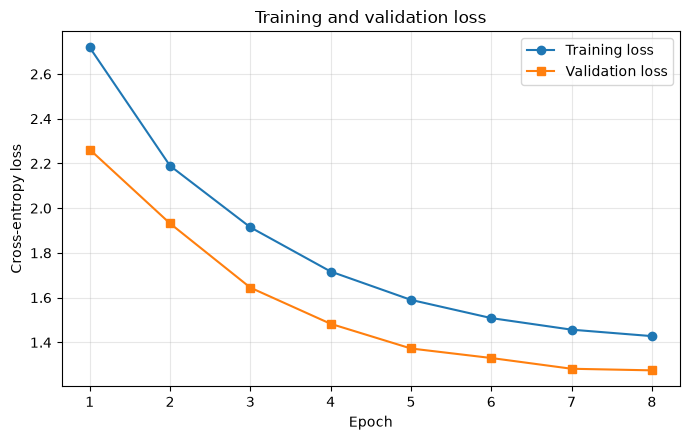

In [12]:
plt.figure(figsize=(7, 4.5))
plt.plot(history["epoch"], history["train_loss"], marker="o", label="Training loss")
plt.plot(history["epoch"], history["val_loss"], marker="s", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss")
plt.title("Training and validation loss"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig("results/loss_curves.png", dpi=150); plt.show()

## 8. Evaluate the model: validation loss and perplexity
**Perplexity = exp(cross-entropy loss).** It can be read as "how many characters the model is effectively choosing between at each step". Lower is better. A model that guesses uniformly has perplexity equal to the vocabulary size.

In [13]:
val_loss   = estimate_loss(model, "val",   cfg_main.block_size, iters=200)
train_loss = estimate_loss(model, "train", cfg_main.block_size, iters=200)

metrics = {
    "parameters": n_params,
    "train_loss": round(train_loss, 4),
    "val_loss": round(val_loss, 4),
    "val_perplexity": round(math.exp(val_loss), 3),
    "val_bits_per_char": round(val_loss / math.log(2), 3),
    "random_guess_perplexity": vocab_size,
    "training_minutes": round(train_secs / 60, 2),
}
for k, v in metrics.items():
    print(f"{k:26s}: {v}")

with open("results/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

parameters                : 818432
train_loss                : 1.2996
val_loss                  : 1.2649
val_perplexity            : 3.543
val_bits_per_char         : 1.825
random_guess_perplexity   : 68
training_minutes          : 30.72


## 9. Generate stories
Give the trained model a starting prompt and let it generate text one character at a time.
- **Temperature** controls randomness (low = safer and more repetitive, high = more creative and more errors).
- **Top-k** limits sampling to the k most likely characters.

In [14]:
def generate_text(m, prompt, max_new_tokens=400, temperature=0.8, top_k=40, seed=None):
    if seed is not None:
        set_seed(seed)
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    out = m.generate(ids, max_new_tokens, temperature=temperature, top_k=top_k, stop_id=eos_id)
    return decode(out[0].tolist()).replace(EOS, "\n[END OF STORY]")

samples = []
for prompt in ["Once upon a time", "One day, a little girl named", "The dog was very"]:
    text = generate_text(model, prompt, max_new_tokens=400, temperature=0.8, top_k=40, seed=1)
    samples.append((prompt, 0.8, text))
    print(f"=== Prompt: {prompt!r} | temperature 0.8 ===")
    print(text, "\n")

=== Prompt: 'Once upon a time' | temperature 0.8 ===
Once upon a time, there was a little girl named Lily. He liked to his who the boy in take a what thought was and to he starts. He saw a gust friends and safed away. She car said so go her came it was very comple the day in the rach. 

The far agreass the dark and unto play and ranged the park. It was dad. Jank his compend color this bild and loved to shoure. He dog and quickly and filly was flue.
[END OF STORY] 

=== Prompt: 'One day, a little girl named' | temperature 0.8 ===
One day, a little girl named Anna and said, "OK, what you smiled. He like to her feell playfuriound and said, "Let's found didn't go move!" 

The big some him the beautiful was finices. He was go sleeping in the rafest. She liked all together it had and for his a red. The can'suon a bear. She for the boy on the bear. Jank was showed he excited and the little boy said, "I'm you are banch day. 

The ready, "Let's the mean be t 

=== Prompt: 'The dog was very' | t

In [15]:
# Effect of temperature on the same prompt
for temp in [0.3, 0.8, 1.3]:
    text = generate_text(model, "Once upon a time", max_new_tokens=300, temperature=temp, top_k=None, seed=7)
    samples.append(("Once upon a time", temp, text))
    print(f"=== temperature {temp} ===")
    print(text, "\n")

with open("results/generated_samples.txt", "w", encoding="utf-8") as f:
    for prompt, temp, text in samples:
        f.write(f"=== Prompt: {prompt!r} | temperature {temp} ===\n{text}\n\n")

=== temperature 0.3 ===
Once upon a time, there was a big said so her mommy with the started and the saw a big started to started to the bard. He was so happy the story and had a smiled the boy and careful was so he had a big came to the best. She was so happy the started to play with the back and said, "I want the be start her fun!"

The 

=== temperature 0.8 ===
Once upon a time there was adventuy tras it and put with beecaus.
[END OF STORY] 

=== temperature 1.3 ===
Once upon a time therought?" Ben, you hanking: spurgwed up in exploge. She had to her an lats. She and Hopps, byou beches vone, they hugerfuly, ""Lethins," Thankim.. Itâ€™t freesces!'C.

They hekis you cemetup with his a snaw iciful chive. He went got play would brut of somether. He was excit its nevo. Theught. On. 



## 10. Experiment with model settings
We now change the **number of layers**, **attention heads** and **training epochs** one at a time (everything else stays the same as the baseline) and observe the effect on loss, perplexity and generated text.

| Group | Runs |
|---|---|
| Layers | 1, 2, 4 (baseline) |
| Attention heads | 1, 4 (baseline), 8 |
| Epochs | short, baseline, long |

All runs use the same seed and the same data. The layer/head runs use the same number of epochs as the baseline so the comparison is fair.

In [16]:
base = dict(vocab_size=vocab_size, block_size=BLOCK_SIZE, n_layer=4, n_head=4, n_embd=128, dropout=0.1)

experiments = [
    # (name,                      changes,            epochs)
    ("Layers: 1",                  dict(n_layer=1),   EXP_EPOCHS),
    ("Layers: 2",                  dict(n_layer=2),   EXP_EPOCHS),
    ("Baseline (4 layers, 4 heads)", dict(),          EXP_EPOCHS),
    ("Heads: 1",                   dict(n_head=1),    EXP_EPOCHS),
    ("Heads: 8",                   dict(n_head=8),    EXP_EPOCHS),
    (f"Epochs: {EXP_SHORT}",       dict(),            EXP_SHORT),
    (f"Epochs: {EXP_LONG}",        dict(),            EXP_LONG),
]

results, histories, exp_models = [], {}, {}
for name, changes, ep in experiments:
    print(f"\n##### {name} #####")
    cfg = GPTConfig(**{**base, **changes})
    m, h, secs = train_model(cfg, epochs=ep, steps_per_epoch=EXP_STEPS, verbose=False)
    final_val = estimate_loss(m, "val", cfg.block_size, iters=100)
    results.append({
        "Experiment": name, "Layers": cfg.n_layer, "Heads": cfg.n_head, "Epochs": ep,
        "Parameters": sum(p.numel() for p in m.parameters()),
        "Val loss": round(final_val, 4), "Val perplexity": round(math.exp(final_val), 3),
        "Time (s)": round(secs),
    })
    histories[name] = h
    exp_models[name] = m
    print(f"val loss {final_val:.4f} | perplexity {math.exp(final_val):.3f} | {secs:.0f}s")

results_df = pd.DataFrame(results)
display(results_df)
results_df.to_csv("results/experiments.csv", index=False)


##### Layers: 1 #####
val loss 1.9706 | perplexity 7.175 | 155s

##### Layers: 2 #####
val loss 1.9562 | perplexity 7.073 | 317s

##### Baseline (4 layers, 4 heads) #####
val loss 1.9268 | perplexity 6.868 | 583s

##### Heads: 1 #####
val loss 1.9196 | perplexity 6.819 | 363s

##### Heads: 8 #####
val loss 1.9354 | perplexity 6.927 | 786s

##### Epochs: 2 #####
val loss 2.2345 | perplexity 9.342 | 267s

##### Epochs: 8 #####
val loss 1.4619 | perplexity 4.314 | 1189s


,Experiment,Layers,Heads,Epochs,Parameters,Val loss,Val perplexity,Time (s)
0,Layers: 1,1,4,4,223616,1.9706,7.175,155
1,Layers: 2,2,4,4,421888,1.9562,7.073,317
2,"Baseline (4 layers, 4 heads)",4,4,4,818432,1.9268,6.868,583
3,Heads: 1,4,1,4,818432,1.9196,6.819,363
4,Heads: 8,4,8,4,818432,1.9354,6.927,786
5,Epochs: 2,4,4,2,818432,2.2345,9.342,267
6,Epochs: 8,4,4,8,818432,1.4619,4.314,1189


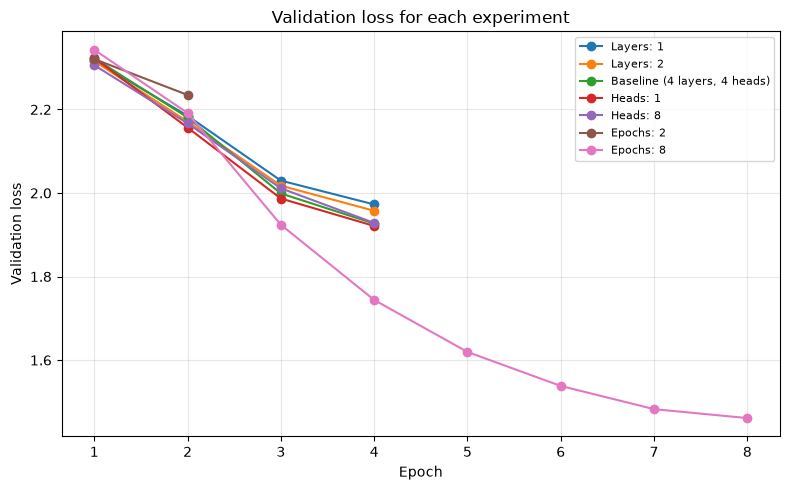

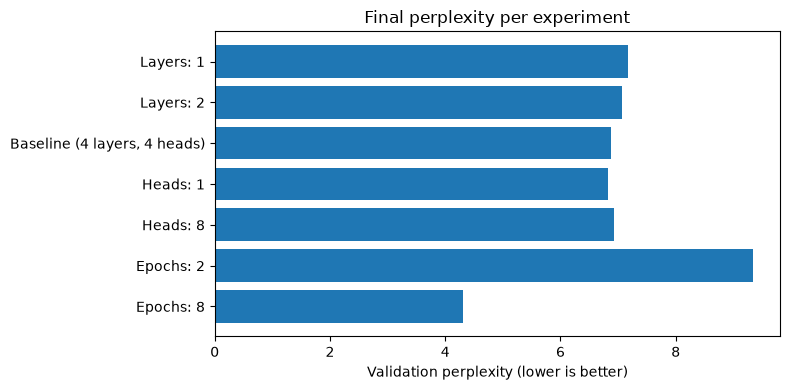

In [17]:
plt.figure(figsize=(8, 5))
for name, h in histories.items():
    plt.plot(h["epoch"], h["val_loss"], marker="o", label=name)
plt.xlabel("Epoch"); plt.ylabel("Validation loss"); plt.title("Validation loss for each experiment")
plt.grid(alpha=0.3); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("results/experiment_val_loss.png", dpi=150); plt.show()

plt.figure(figsize=(8, 4))
plt.barh(results_df["Experiment"], results_df["Val perplexity"])
plt.xlabel("Validation perplexity (lower is better)"); plt.title("Final perplexity per experiment")
plt.gca().invert_yaxis(); plt.tight_layout()
plt.savefig("results/experiment_perplexity.png", dpi=150); plt.show()

### Generated text from each experiment
Same prompt, same sampling seed and temperature, so differences come from the model.

In [18]:
exp_samples = []
for name, m in exp_models.items():
    text = generate_text(m, "Once upon a time", max_new_tokens=250, temperature=0.8, top_k=40, seed=3)
    exp_samples.append((name, text))
    print(f"=== {name} ===")
    print(text, "\n")

with open("results/experiment_samples.txt", "w", encoding="utf-8") as f:
    for name, text in exp_samples:
        f.write(f"=== {name} ===\n{text}\n\n")

=== Layers: 1 ===
Once upon a timend gre!
[END OF STORY] 

=== Layers: 2 ===
Once upon a time fog bout in hid not gand a plower and the cand fourk frul. He lickilound wh assoo se thar. It"
" andin the tom was the iroo ke and and mitt he was aing deca fry hend momeled prith to kell and the arr gond bere. They acil wins proo the the fand frore 

=== Baseline (4 layers, 4 heads) ===
Once upon a time fog bout in hid nous.

One ayd lerayd the cay the an frul hen licll oxplon. Shed the the to seell trin the tom he the and like and and an they wase he to a they hend momeled to thine kel to and frand a, fand be hand acil wins thas tre the fand the b 

=== Heads: 1 ===
Once upon a time fog bout in hid nous.

One day, domy rou they the and ruld gid wh ito sa wheass o sant sare send and. The an mucked. He don kexce rand, sand Bend has to tha fey hend momeled to the eve the tanked and go fther sthe to cil wins the furen ak fand the b 

=== Heads: 8 ===
Once upon a time fog bout in hid noul, the sp

## 11. Save the trained model
We save the **parameters and the configuration** (plus the vocabulary, which is needed to turn text into ids) so the model can generate text later without retraining.

In [19]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "config": asdict(cfg_main),
    "chars": chars,
    "eos_id": eos_id,
}
torch.save(checkpoint, "tinystories_gpt.pt")
with open("model_config.json", "w") as f:
    json.dump({"config": asdict(cfg_main), "vocab_size": vocab_size, "metrics": metrics}, f, indent=2)
print("Saved: tinystories_gpt.pt  and  model_config.json")
print(f"Checkpoint size: {os.path.getsize('tinystories_gpt.pt')/1e6:.1f} MB")

try:
    from google.colab import files
    files.download("tinystories_gpt.pt"); files.download("model_config.json")
except Exception as e:
    print("(Not running in Colab, skipping download):", e)

Saved: tinystories_gpt.pt  and  model_config.json
Checkpoint size: 3.6 MB
(Not running in Colab, skipping download): No module named 'google'


### Reload the saved model and check it
Rebuild the model from the saved configuration, load the weights, and confirm it gives the same predictions as the model in memory.

In [20]:
ckpt = torch.load("tinystories_gpt.pt", map_location=device)
loaded = GPT(GPTConfig(**ckpt["config"])).to(device)
loaded.load_state_dict(ckpt["model_state_dict"])
loaded.eval(); model.eval()

x, _ = get_batch("val", batch_size=4)
with torch.no_grad():
    same = torch.allclose(model(x)[0], loaded(x)[0], atol=1e-5)
print("Reloaded model gives identical outputs:", same)
print()
print(generate_text(loaded, "Once upon a time", max_new_tokens=250, temperature=0.8, top_k=40, seed=11))

Reloaded model gives identical outputs: True

Once upon a time, "That made the ma and said, "Lily you wilth you can the got time," The raving said. "Whow, we you can bug tried, the was put ground around the could betty negart.

The mom we happy the time trach a shiny and said, â€œMom says, "We det to the can pl


## Optional: Chat window with Gradio
A simple chat window: type the beginning of a story and the model continues it. Use the sliders to change the length and the temperature. Running this cell prints a public link you can open in your browser (it stays alive while the cell is running).

In [21]:
import gradio as gr

def chat_fn(message, history, max_new_tokens, temperature, top_k):
    return generate_text(model, message, max_new_tokens=int(max_new_tokens),
                         temperature=float(temperature), top_k=int(top_k))

demo = gr.ChatInterface(
    fn=chat_fn,
    title="Tiny Story Teller (character-level Transformer)",
    description="Type the start of a story, for example: Once upon a time",
    additional_inputs=[
        gr.Slider(50, 800, value=300, step=10, label="Max new characters"),
        gr.Slider(0.3, 1.5, value=0.8, step=0.05, label="Temperature"),
        gr.Slider(1, vocab_size, value=40, step=1, label="Top-k"),
    ],
)
demo.launch(share=True)   # stop the cell when you have taken your screenshots

* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/11/17 16:24:02 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: i/o timeout


## Discussion: mechanisms that improve performance

**In the model architecture**
- **Self-attention** lets every character use information from all earlier characters in the window, so the model can learn relationships (for example, the name of a character introduced earlier in the story) that a fixed-size window of previous characters could not capture.
- **Multi-head attention** runs several attention operations in parallel, so different heads can focus on different patterns.
- **Causal masking** stops the model from seeing future tokens, so training matches how text is generated.
- **Positional embeddings** give the model word-order information, because attention on its own ignores order.
- **Feed-forward layers** add non-linear processing at every position.
- **Residual connections** and **layer normalization** make deeper models trainable by keeping gradients stable.
- **Weight tying** shares the token-embedding and output matrices, which reduces parameters and often helps small models.

**In training**
- **AdamW** adapts the step size for every parameter and decouples weight decay.
- **Learning-rate warm-up and cosine decay** avoid unstable early updates and let training settle at the end.
- **Gradient clipping** prevents rare large gradients from destabilising training.
- **Dropout** and **weight decay** reduce overfitting.
- **Validation loss monitoring** shows when the model stops generalising.

**In generation**
- **Temperature** and **top-k sampling** trade off safety against creativity and reduce nonsense characters.

**Scale:** more data, more layers, a larger embedding size and longer training generally lower the loss (see the experiments in Task 10).

## Notes for the README (fill in after running)
- What loss and perplexity did the main model reach? Did the validation loss stay close to the training loss?
- How did the generated text look at the start of training compared with the end? (grammar, spelling, repeated phrases)
- Which setting changed the loss most: layers, heads or epochs?
- What problems did you run into (GPU, memory, time)?
- Why is a character-level model weaker than a word or sub-word one?

## Download your results
Run this cell last. It zips the `results/` folder (loss curves, metrics, generated samples, experiment tables) so you can download it for your GitHub portfolio.

In [22]:
import shutil
shutil.make_archive("lab3_results", "zip", "results")
print("Created lab3_results.zip with:", sorted(os.listdir("results")))
try:
    from google.colab import files
    files.download("lab3_results.zip")
except Exception as e:
    print("(Not running in Colab, skipping download):", e)

Created lab3_results.zip with: ['dataset_lengths.png', 'experiment_perplexity.png', 'experiment_samples.txt', 'experiment_val_loss.png', 'experiments.csv', 'generated_samples.txt', 'loss_curves.png', 'metrics.json']
(Not running in Colab, skipping download): No module named 'google'
